In [12]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import pennylane as qml
import matplotlib.pyplot as plt
import os
import pandas as pd
from sklearn.model_selection import train_test_split


In [ ]:
path = "data/ml-100k"

ratings = pd.read_csv(
    f"{path}/u.data",
    sep="\t",
    names=["user_id", "item_id", "rating", "timestamp"]
)

print(f"Ratings: {len(ratings):,}")
print(f"Users:   {ratings['user_id'].nunique()}")
print(f"Movies:  {ratings['item_id'].nunique()}")
print(f"Mean rating: {ratings['rating'].mean():.4f}")

ratings.head()

#  Index maps for PyTorch
user_ids  = ratings["user_id"].unique()
movie_ids = ratings["item_id"].unique()

user_to_idx  = {u: i for i, u in enumerate(user_ids)}
movie_to_idx = {m: i for i, m in enumerate(movie_ids)}

ratings["user_idx"]  = ratings["user_id"].map(user_to_idx)
ratings["movie_idx"] = ratings["item_id"].map(movie_to_idx)

n_users  = len(user_ids)
n_movies = len(movie_ids)
global_mean = float(ratings["rating"].mean())

# Shared train/test split
train_df, test_df = train_test_split(ratings, test_size=0.2, random_state=42)

# PyTorch tensors
train_users   = torch.tensor(train_df["user_idx"].values,  dtype=torch.long)
train_movies  = torch.tensor(train_df["movie_idx"].values, dtype=torch.long)
train_ratings = torch.tensor(train_df["rating"].values,    dtype=torch.float32)

test_users    = torch.tensor(test_df["user_idx"].values,   dtype=torch.long)
test_movies   = torch.tensor(test_df["movie_idx"].values,  dtype=torch.long)
test_ratings  = torch.tensor(test_df["rating"].values,     dtype=torch.float32)

print("Train size:", len(train_df))
print("Test size: ", len(test_df))

Ratings: 100,000
Users:   943
Movies:  1682
Mean rating: 3.5299
Train size: 80000
Test size:  20000


In [20]:
class MatrixFactorization(nn.Module):
    """
    Biased Matrix Factorisation — mirrors Surprise SVD exactly.

    Formula:  r_hat = mu + b_u + b_i + p_u · q_i

    Parameters
    ----------
    n_users     : number of unique users  → rows of P
    n_movies    : number of unique movies → rows of Q
    n_factors   : latent dimension k
    rating_mean : dataset mean, used to fix global bias mu
    """

    def __init__(self, n_users, n_movies, n_factors=50, rating_mean=train_df["rating"].mean()):
        super().__init__()

        # P — user latent factors
        self.user_factors  = nn.Embedding(n_users,  n_factors)
        # Q — item latent factors
        self.movie_factors = nn.Embedding(n_movies, n_factors)

        # b_u —  user bias
        self.user_bias  = nn.Embedding(n_users,  1)

        # b_i — item bias
        self.movie_bias = nn.Embedding(n_movies, 1)

        # mu — global mean rating, fixed
        self.register_buffer("global_bias", torch.tensor(rating_mean, dtype=torch.float32))

        # small random init for factors, zero for biases
        nn.init.normal_(self.user_factors.weight,  std=0.01)
        nn.init.normal_(self.movie_factors.weight, std=0.01)
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.movie_bias.weight)

    def forward(self, users, movies, return_dot=False):
        p_u = self.user_factors(users)
        q_i = self.movie_factors(movies)

        dot = (p_u * q_i).sum(dim=1)

        b_u = self.user_bias(users).squeeze(-1)
        b_i = self.movie_bias(movies).squeeze(-1)

        pred = self.global_bias + b_u + b_i + dot

        if return_dot:
            return pred, dot

        return pred

In [21]:
def explicit_loss(pred, target, model, users, movies, lam=0.02):
    """
    Regularised MSE — explicit version of Surprise's internal objective.

    L = (1/N) * sum((r - r_hat)^2) + lambda * (||p_u||^2 + ||q_i||^2 + b_u^2 + b_i^2)
    """
    # reconstruction error
    mse = ((pred - target) ** 2).mean()

    # regularisation term
    p_u = model.user_factors(users)
    q_i = model.movie_factors(movies)
    b_u = model.user_bias(users).squeeze(-1)
    b_i = model.movie_bias(movies).squeeze(-1)

    reg = lam * (
        (p_u ** 2).mean() +
        (q_i ** 2).mean() +
        (b_u ** 2).mean() +
        (b_i ** 2).mean()
    )

    return mse + reg


In [22]:
# Train
model_pytorch = MatrixFactorization(
    n_users, n_movies,
    n_factors=50,
    rating_mean=global_mean
)

# optimizer = torch.optim.SGD(model_pytorch.parameters(), lr=0.005)
optimizer = torch.optim.Adam(model_pytorch.parameters(), lr=0.001)
epochs = 180
lam    = 0.002

for epoch in range(epochs):
    model_pytorch.train()
    optimizer.zero_grad()

    preds, dots = model_pytorch(train_users, train_movies, return_dot=True)
    loss  = explicit_loss(preds, train_ratings, model_pytorch,
                          train_users, train_movies, lam=lam)

    loss.backward()
    optimizer.step()

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1:3d}/{epochs} | Loss: {loss.item():.4f}")

Epoch   5/180 | Loss: 1.2613
Epoch  10/180 | Loss: 1.2524
Epoch  15/180 | Loss: 1.2426
Epoch  20/180 | Loss: 1.2317
Epoch  25/180 | Loss: 1.2191
Epoch  30/180 | Loss: 1.2048
Epoch  35/180 | Loss: 1.1882
Epoch  40/180 | Loss: 1.1694
Epoch  45/180 | Loss: 1.1482
Epoch  50/180 | Loss: 1.1248
Epoch  55/180 | Loss: 1.0992
Epoch  60/180 | Loss: 1.0719
Epoch  65/180 | Loss: 1.0432
Epoch  70/180 | Loss: 1.0138
Epoch  75/180 | Loss: 0.9841
Epoch  80/180 | Loss: 0.9546
Epoch  85/180 | Loss: 0.9258
Epoch  90/180 | Loss: 0.8980
Epoch  95/180 | Loss: 0.8713
Epoch 100/180 | Loss: 0.8460
Epoch 105/180 | Loss: 0.8219
Epoch 110/180 | Loss: 0.7990
Epoch 115/180 | Loss: 0.7772
Epoch 120/180 | Loss: 0.7565
Epoch 125/180 | Loss: 0.7366
Epoch 130/180 | Loss: 0.7176
Epoch 135/180 | Loss: 0.6993
Epoch 140/180 | Loss: 0.6815
Epoch 145/180 | Loss: 0.6644
Epoch 150/180 | Loss: 0.6477
Epoch 155/180 | Loss: 0.6314
Epoch 160/180 | Loss: 0.6156
Epoch 165/180 | Loss: 0.6001
Epoch 170/180 | Loss: 0.5850
Epoch 175/180 

In [23]:
# Evaluate
model_pytorch.eval()
with torch.no_grad():
    test_preds_pt = model_pytorch(test_users, test_movies)
    rmse_pytorch  = torch.sqrt(((test_preds_pt - test_ratings) ** 2).mean()).item()

print(f"Model (PyTorch)  →  RMSE: {rmse_pytorch:.4f}")

Model (PyTorch)  →  RMSE: 0.9394


In [24]:
model_pytorch.eval()

with torch.no_grad():
    train_preds, train_dots = model_pytorch(
        train_users,
        train_movies,
        return_dot=True
    )

train_dots_np = train_dots.cpu().numpy()

print(train_dots_np.shape)
print(train_dots_np.min(), train_dots_np.max())
print(train_dots_np[:10])

(80000,)
-2.3972197 1.7020643
[-0.6073895   0.8488761   0.12344929  0.42740598  0.5018873   0.4991058
 -0.72391033 -0.09918144 -0.8204521   0.42540312]


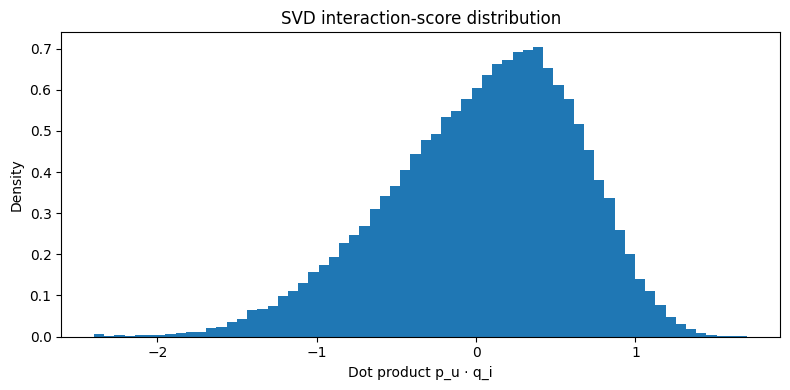

In [25]:
plt.figure(figsize=(8, 4))
plt.hist(train_dots_np, bins=64, density=True)
plt.xlabel("Dot product p_u · q_i")
plt.ylabel("Density")
plt.title("SVD interaction-score distribution")
plt.tight_layout()
plt.show()

In [40]:
import numpy as np
import torch
import torch.nn as nn
import pennylane as qml
import matplotlib.pyplot as plt
import os
import copy
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

In [27]:
# -----------------------------
# 1. Prepare dot-product target distribution
# -----------------------------

train_dots_np = train_dots_np.astype(np.float32)

n_qubits = 6
num_bins = 2 ** n_qubits
num_layers = 8

dot_min = train_dots_np.min()
dot_max = train_dots_np.max()

bin_edges = np.linspace(dot_min, dot_max, num_bins + 1)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

hist, _ = np.histogram(train_dots_np, bins=bin_edges)
target_dist = hist.astype(np.float32)
target_dist = target_dist / target_dist.sum()

target_dist_torch = torch.tensor(target_dist, dtype=torch.float32)

print("Dot-product range:", dot_min, dot_max)
print("Target distribution shape:", target_dist.shape)
print("Target distribution sum:", target_dist.sum())

Dot-product range: -2.3972197 1.7020643
Target distribution shape: (64,)
Target distribution sum: 1.0


In [28]:
# -----------------------------
# 2. Define Q-Prior circuit
# -----------------------------

dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="torch")
def dot_qprior_circuit(params):
    for layer in range(num_layers):
        for i in range(n_qubits):
            qml.RY(params[layer, i, 0], wires=i)
            qml.RZ(params[layer, i, 1], wires=i)
            qml.RX(params[layer, i, 2], wires=i)

        for i in range(n_qubits - 1):
            qml.CNOT(wires=[i, i + 1])

    return qml.probs(wires=range(n_qubits))


class DotProductQPrior(nn.Module):
    def __init__(self):
        super().__init__()
        self.params = nn.Parameter(
            0.01 * torch.randn(num_layers, n_qubits, 3)
        )

    def forward(self):
        return dot_qprior_circuit(self.params)

In [29]:
# -----------------------------
# 3. Train Q-Prior
# -----------------------------

qprior_model = DotProductQPrior()
optimizer = torch.optim.Adam(qprior_model.parameters(), lr=0.01)

qprior_epochs = 500
loss_history = []

for epoch in range(qprior_epochs):
    qprior_model.train()
    optimizer.zero_grad()

    learned_dist = qprior_model()

    loss = torch.sum((learned_dist - target_dist_torch) ** 2)

    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch {epoch+1:3d}/{qprior_epochs} | "
            f"QPrior Loss: {loss.item():.8f}"
        )

learned_dot_qprior = qprior_model().detach().cpu().numpy()

print("Learned Q-Prior shape:", learned_dot_qprior.shape)
print("Learned Q-Prior sum:", learned_dot_qprior.sum())

Epoch  50/500 | QPrior Loss: 0.01895019
Epoch 100/500 | QPrior Loss: 0.00579522
Epoch 150/500 | QPrior Loss: 0.00308444
Epoch 200/500 | QPrior Loss: 0.00190254
Epoch 250/500 | QPrior Loss: 0.00115928
Epoch 300/500 | QPrior Loss: 0.00080715
Epoch 350/500 | QPrior Loss: 0.00061714
Epoch 400/500 | QPrior Loss: 0.00049270
Epoch 450/500 | QPrior Loss: 0.00040057
Epoch 500/500 | QPrior Loss: 0.00032857
Learned Q-Prior shape: (64,)
Learned Q-Prior sum: 1.0000007220714575


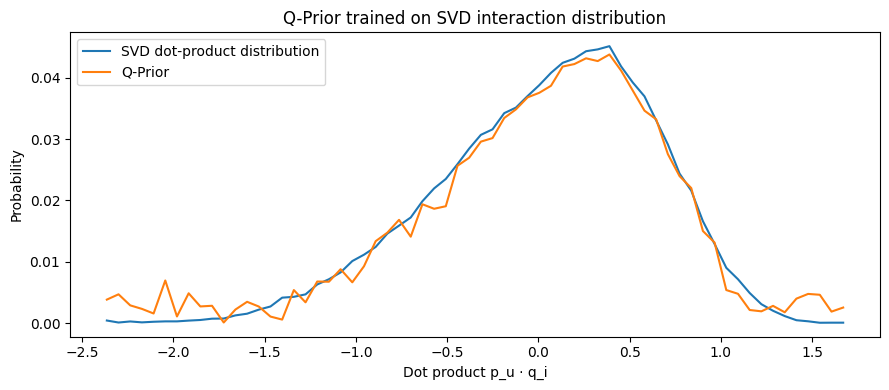

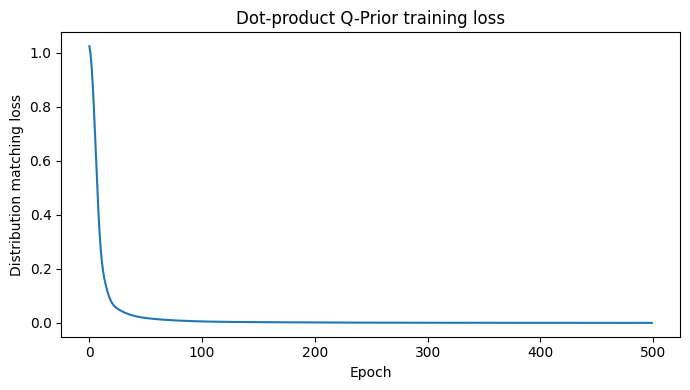

In [30]:
# -----------------------------
# 4. Plot target vs Q-Prior
# -----------------------------

plt.figure(figsize=(9, 4))
plt.plot(bin_centers, target_dist, label="SVD dot-product distribution")
plt.plot(bin_centers, learned_dot_qprior, label="Q-Prior")
plt.xlabel("Dot product p_u · q_i")
plt.ylabel("Probability")
plt.title("Q-Prior trained on SVD interaction distribution")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Distribution matching loss")
plt.title("Dot-product Q-Prior training loss")
plt.tight_layout()
plt.show()

In [31]:
# -----------------------------
# 5. Save Q-Prior result
# -----------------------------

os.makedirs("models/qprior_svd_dot", exist_ok=True)

np.save("models/qprior_svd_dot/dot_qprior.npy", learned_dot_qprior)
np.save("models/qprior_svd_dot/dot_bin_centers.npy", bin_centers)
np.save("models/qprior_svd_dot/dot_bin_edges.npy", bin_edges)
np.save("models/qprior_svd_dot/dot_target_dist.npy", target_dist)

torch.save(
    qprior_model.state_dict(),
    "models/qprior_svd_dot/dot_qprior_model.pt"
)

print("Saved:")
print("models/qprior_svd_dot/dot_qprior.npy")
print("models/qprior_svd_dot/dot_bin_centers.npy")
print("models/qprior_svd_dot/dot_bin_edges.npy")
print("models/qprior_svd_dot/dot_target_dist.npy")
print("models/qprior_svd_dot/dot_qprior_model.pt")

Saved:
models/qprior_svd_dot/dot_qprior.npy
models/qprior_svd_dot/dot_bin_centers.npy
models/qprior_svd_dot/dot_bin_edges.npy
models/qprior_svd_dot/dot_target_dist.npy
models/qprior_svd_dot/dot_qprior_model.pt


In [32]:
qprior_dist = np.load("models/qprior_svd_dot/dot_qprior.npy")
bin_centers = np.load("models/qprior_svd_dot/dot_bin_centers.npy")

In [ ]:
# Prepare Q-Prior tensors

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

qprior_dist_torch = torch.tensor(qprior_dist, dtype=torch.float32, device=device)
qprior_dist_torch = qprior_dist_torch / qprior_dist_torch.sum()

bin_centers_torch = torch.tensor(bin_centers, dtype=torch.float32, device=device)

train_users = train_users.to(device)
train_movies = train_movies.to(device)
train_ratings = train_ratings.to(device)

test_users = test_users.to(device)
test_movies = test_movies.to(device)
test_ratings = test_ratings.to(device)

In [ ]:
# Differentiable dot-product distribution
def soft_dot_distribution(dots, bin_centers, bandwidth=None):
    """
    Differentiable histogram for dot products p_u · q_i.
    Returns P_model(dot).
    """
    if bandwidth is None:
        bin_width = bin_centers[1] - bin_centers[0]
        bandwidth = 2.0 * bin_width

    z = (dots.unsqueeze(1) - bin_centers.unsqueeze(0)) / bandwidth

    logits = -0.5 * (z ** 2)
    soft_bins = F.softmax(logits, dim=1)

    dot_dist = soft_bins.mean(dim=0)
    dot_dist = dot_dist / dot_dist.sum()

    return dot_dist


def kl_divergence(pred_dist, target_dist, eps=1e-8):
    pred_dist = torch.clamp(pred_dist, eps, 1.0)
    target_dist = torch.clamp(target_dist, eps, 1.0)

    return torch.sum(pred_dist * torch.log(pred_dist / target_dist))

In [ ]:
# New SVD + Q-Prior loss
def explicit_loss_with_dot_qprior(
    pred,
    target,
    dot,
    model,
    users,
    movies,
    qprior_dist,
    bin_centers,
    lam=0.002,
    lambda_qprior=0.05,
):
    mse = ((pred - target) ** 2).mean()

    p_u = model.user_factors(users)
    q_i = model.movie_factors(movies)
    b_u = model.user_bias(users).squeeze(-1)
    b_i = model.movie_bias(movies).squeeze(-1)

    reg = lam * (
        (p_u ** 2).mean()
        + (q_i ** 2).mean()
        + (b_u ** 2).mean()
        + (b_i ** 2).mean()
    )

    dot_dist = soft_dot_distribution(dot, bin_centers)

    qprior_kl = kl_divergence(dot_dist, qprior_dist)

    total_loss = mse + reg + lambda_qprior * qprior_kl

    return total_loss, mse, reg, qprior_kl, dot_dist

In [44]:
model_qprior = copy.deepcopy(model_pytorch)
model_qprior = model_qprior.to(device)

optimizer = torch.optim.Adam(model_qprior.parameters(), lr=0.0005)

fine_tune_epochs = 80

lam = 0.002
lambda_qprior = 0.1

history = {
    "loss": [],
    "mse": [],
    "reg": [],
    "kl": [],
    "test_rmse": [],
    "test_mae": [],
}

for epoch in range(fine_tune_epochs):
    model_qprior.train()
    optimizer.zero_grad()

    preds, dots = model_qprior(
        train_users,
        train_movies,
        return_dot=True
    )

    loss, mse, reg, qprior_kl, train_dot_dist = explicit_loss_with_dot_qprior(
        pred=preds,
        target=train_ratings,
        dot=dots,
        model=model_qprior,
        users=train_users,
        movies=train_movies,
        qprior_dist=qprior_dist_torch,
        bin_centers=bin_centers_torch,
        lam=lam,
        lambda_qprior=lambda_qprior,
    )

    loss.backward()
    optimizer.step()

    model_qprior.eval()
    with torch.no_grad():
        test_preds, test_dots = model_qprior(
            test_users,
            test_movies,
            return_dot=True
        )

        test_rmse = torch.sqrt(((test_preds - test_ratings) ** 2).mean())
        test_mae = torch.abs(test_preds - test_ratings).mean()

        test_dot_dist = soft_dot_distribution(
            test_dots,
            bin_centers_torch
        )

        test_kl = kl_divergence(test_dot_dist, qprior_dist_torch)

    history["loss"].append(loss.item())
    history["mse"].append(mse.item())
    history["reg"].append(reg.item())
    history["kl"].append(qprior_kl.item())
    history["test_rmse"].append(test_rmse.item())
    history["test_mae"].append(test_mae.item())

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch {epoch+1:3d}/{fine_tune_epochs} | "
            f"Loss: {loss.item():.4f} | "
            f"MSE: {mse.item():.4f} | "
            f"Reg: {reg.item():.6f} | "
            f"Train KL: {qprior_kl.item():.6f} | "
            f"Test RMSE: {test_rmse.item():.4f} | "
            f"Test MAE: {test_mae.item():.4f} | "
            f"Test KL: {test_kl.item():.6f}"
        )

Epoch   5/80 | Loss: 0.5526 | MSE: 0.5475 | Reg: 0.000187 | Train KL: 0.049318 | Test RMSE: 0.9391 | Test MAE: 0.7384 | Test KL: 0.061749
Epoch  10/80 | Loss: 0.5462 | MSE: 0.5411 | Reg: 0.000190 | Train KL: 0.048918 | Test RMSE: 0.9388 | Test MAE: 0.7380 | Test KL: 0.060209
Epoch  15/80 | Loss: 0.5398 | MSE: 0.5348 | Reg: 0.000193 | Train KL: 0.048575 | Test RMSE: 0.9386 | Test MAE: 0.7378 | Test KL: 0.058864
Epoch  20/80 | Loss: 0.5336 | MSE: 0.5286 | Reg: 0.000196 | Train KL: 0.048274 | Test RMSE: 0.9385 | Test MAE: 0.7376 | Test KL: 0.057695
Epoch  25/80 | Loss: 0.5275 | MSE: 0.5225 | Reg: 0.000199 | Train KL: 0.048011 | Test RMSE: 0.9384 | Test MAE: 0.7375 | Test KL: 0.056679
Epoch  30/80 | Loss: 0.5215 | MSE: 0.5165 | Reg: 0.000202 | Train KL: 0.047787 | Test RMSE: 0.9384 | Test MAE: 0.7374 | Test KL: 0.055795
Epoch  35/80 | Loss: 0.5155 | MSE: 0.5106 | Reg: 0.000205 | Train KL: 0.047608 | Test RMSE: 0.9384 | Test MAE: 0.7373 | Test KL: 0.055023
Epoch  40/80 | Loss: 0.5096 | MSE:

In [45]:
model_pytorch = model_pytorch.to(device)
model_pytorch.eval()
model_qprior.eval()

with torch.no_grad():
    base_preds, base_dots = model_pytorch(
        test_users,
        test_movies,
        return_dot=True
    )

    qprior_preds, qprior_dots = model_qprior(
        test_users,
        test_movies,
        return_dot=True
    )

    base_rmse = torch.sqrt(((base_preds - test_ratings) ** 2).mean())
    base_mae = torch.abs(base_preds - test_ratings).mean()

    qprior_rmse = torch.sqrt(((qprior_preds - test_ratings) ** 2).mean())
    qprior_mae = torch.abs(qprior_preds - test_ratings).mean()

    base_dot_dist = soft_dot_distribution(base_dots, bin_centers_torch)
    qprior_dot_dist = soft_dot_distribution(qprior_dots, bin_centers_torch)

    base_kl = kl_divergence(base_dot_dist, qprior_dist_torch)
    qprior_kl = kl_divergence(qprior_dot_dist, qprior_dist_torch)

print("Baseline SVD")
print(f"RMSE: {base_rmse.item():.4f}")
print(f"MAE : {base_mae.item():.4f}")
print(f"KL  : {base_kl.item():.6f}")

print("\nSVD + Dot-product Q-Prior")
print(f"RMSE: {qprior_rmse.item():.4f}")
print(f"MAE : {qprior_mae.item():.4f}")
print(f"KL  : {qprior_kl.item():.6f}")

Baseline SVD
RMSE: 0.9394
MAE : 0.7388
KL  : 0.063486

SVD + Dot-product Q-Prior
RMSE: 0.9402
MAE : 0.7386
KL  : 0.051000


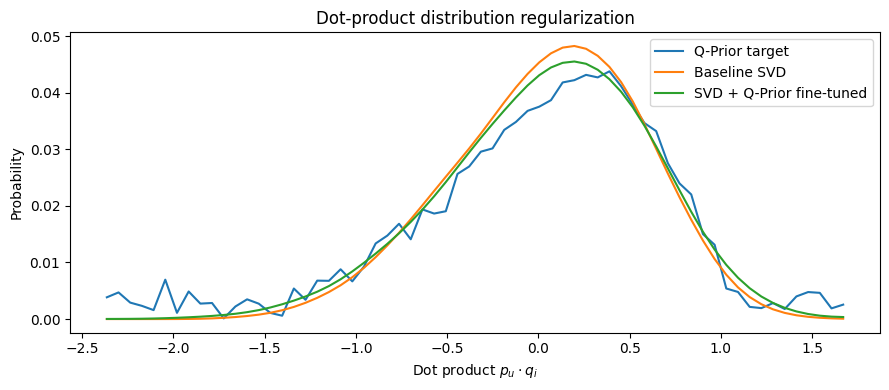

In [46]:
plt.figure(figsize=(9, 4))

plt.plot(
    bin_centers,
    qprior_dist_torch.detach().cpu().numpy(),
    label="Q-Prior target"
)

plt.plot(
    bin_centers,
    base_dot_dist.detach().cpu().numpy(),
    label="Baseline SVD"
)

plt.plot(
    bin_centers,
    qprior_dot_dist.detach().cpu().numpy(),
    label="SVD + Q-Prior fine-tuned"
)

plt.xlabel("Dot product $p_u \\cdot q_i$")
plt.ylabel("Probability")
plt.title("Dot-product distribution regularization")
plt.legend()
plt.tight_layout()
plt.show()